# 02 · Signal Quality

**Question:** which windows of which signals can be trusted?

Phase 1 showed that Empatica's HR is often implausible during cycling. Before comparing any physiology between
conditions, every 30-s window gets a quality verdict per signal. The rules use **signal properties only**, never
the expected physiological result. Excluding data because it "doesn't look physiological" would be circular.
Plausibility is examined separately, as a sensitivity check at the end.

Inputs: `data/processed/windows_raw.csv`, built by `python -m src.pipeline`. That is 12,346 windows of 30 s
(15-s step) cut inside tag-defined segments, after the repairs listed in `src/data/repairs.py`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.visualization import plots as P

P.set_style()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
PROCESSED = ROOT / "data" / "processed"; INTERIM = ROOT / "data" / "interim"
C = P.COND_COLORS

from src.signals import quality as Q
from src.data.repairs import load_clean_session
from src.signals.processing import dominant_frequency

raw = pd.read_csv(PROCESSED / "windows_raw.csv")
w = Q.add_quality_flags(raw)
w.to_csv(PROCESSED / "windows.csv", index=False)
print(f"{len(w):,} windows · {w.subject_id.nunique()} participants · {w.groupby(['condition','session_id']).ngroups} sessions")

12,346 windows · 36 participants · 100 sessions


## 1 · What a good and a bad PPG window look like

The wrist PPG (BVP) should be quasi-periodic at the heart rate. The **spectral quality index (SQI)** is the share of
cardiac-band power concentrated at the dominant frequency and its first harmonic: near 1 means a clean pulse, near 0
means broadband noise. The same participant (S04), three moments:

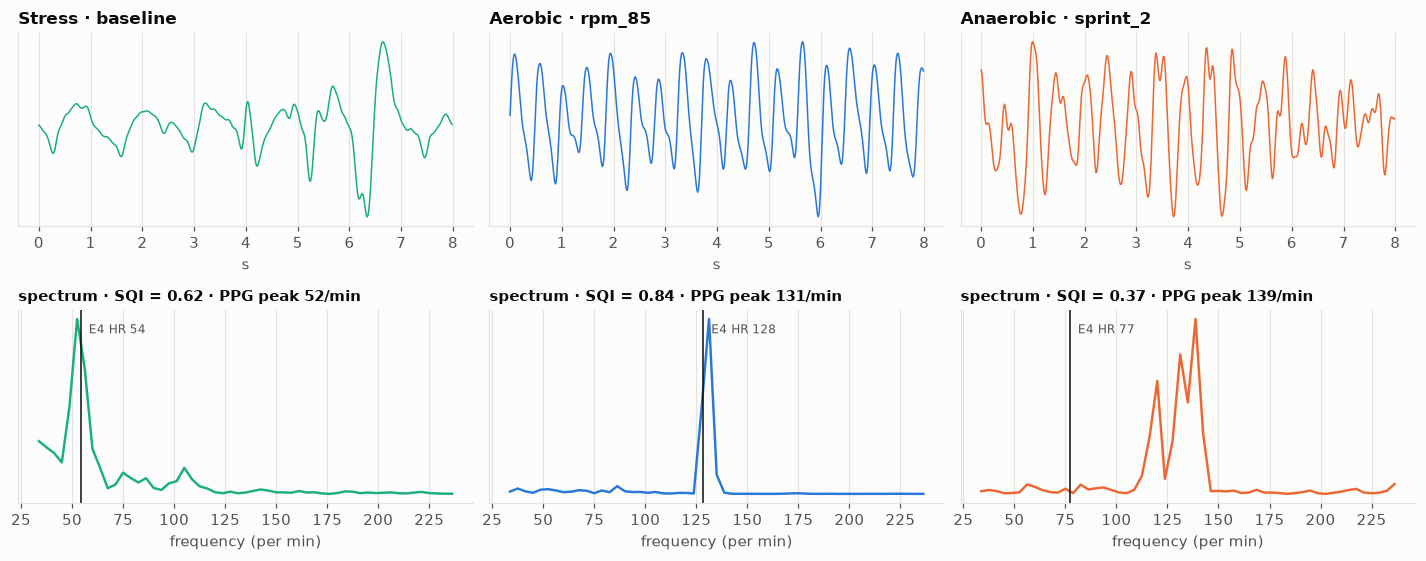

In [2]:
examples = [("STRESS", "S04", "baseline", 60), ("AEROBIC", "S04", "rpm_85", 60), ("ANAEROBIC", "S04", "sprint_2", 5)]
seg = pd.read_csv(INTERIM / "segments.csv")
fig, axes = plt.subplots(2, 3, figsize=(13, 5.2), gridspec_kw=dict(height_ratios=[1, 1]))
for j, (cond, sid, segname, off) in enumerate(examples):
    s, inv = load_clean_session(cond, sid)
    r = seg[(seg.condition == cond) & (seg.session_id == sid) & (seg.segment == segname)].iloc[0]
    t0 = r.start_s + off
    x = s.signals["BVP"].data.BVP.loc[t0:t0 + 30].to_numpy()
    f0, sqi = dominant_frequency(x, 64)
    hr_e4 = s.signals["HR"].data.HR.loc[t0 - 10:t0 + 20].mean()
    ax = axes[0, j]
    tt = np.arange(len(x)) / 64
    ax.plot(tt[:64 * 8], x[:64 * 8], color=C[cond], lw=1)
    ax.set_title(f"{cond.title()} · {segname}", loc="left")
    ax.set_xlabel("s"); ax.set_yticks([])
    from scipy.signal import welch
    fr, pw = welch(x - x.mean(), fs=64, nperseg=64 * 16)
    m = (fr > 0.5) & (fr < 4)
    axes[1, j].plot(fr[m] * 60, pw[m] / pw[m].max(), color=C[cond], lw=1.6)
    axes[1, j].axvline(hr_e4, color=P.TEXT, lw=1, ls="-")
    axes[1, j].text(hr_e4 + 4, 0.88, f"E4 HR {hr_e4:.0f}", fontsize=8, color=P.TEXT_2, transform=axes[1, j].get_xaxis_transform())
    axes[1, j].set_xlabel("frequency (per min)"); axes[1, j].set_yticks([])
    axes[1, j].set_title(f"spectrum · SQI = {sqi:.2f} · PPG peak {f0*60:.0f}/min", loc="left", fontsize=10)
fig.tight_layout(); P.save(fig, "02_ppg_examples"); plt.show()

Seated, the PPG shows clean pulses and a single spectral peak that matches Empatica's HR. While pedalling, the pulse
is still visible but noisier. During a sprint, forearm and grip forces swamp the optical signal. The spectrum is
broadband, and the dominant peak no longer corresponds to the heart.

## 2 · Calibrating the thresholds on clean data

Reference set: **seated windows (stress-protocol baseline and rests) in which Empatica itself validated ≥ 70% of the
beats** (IBI coverage). These are the closest thing to ground truth in this dataset. Thresholds are taken from their
distribution, not tuned to make results look good:
- `bvp_sqi ≥ 0.40`: 5th percentile of the reference
- `|E4 HR − PPG dominant frequency| ≤ 10 bpm`: ≈ 95th percentile of the reference

Reference windows: 2,034 from 34 participants
SQI 5th percentile: 0.405 | agreement 95th percentile (bpm): 10.6


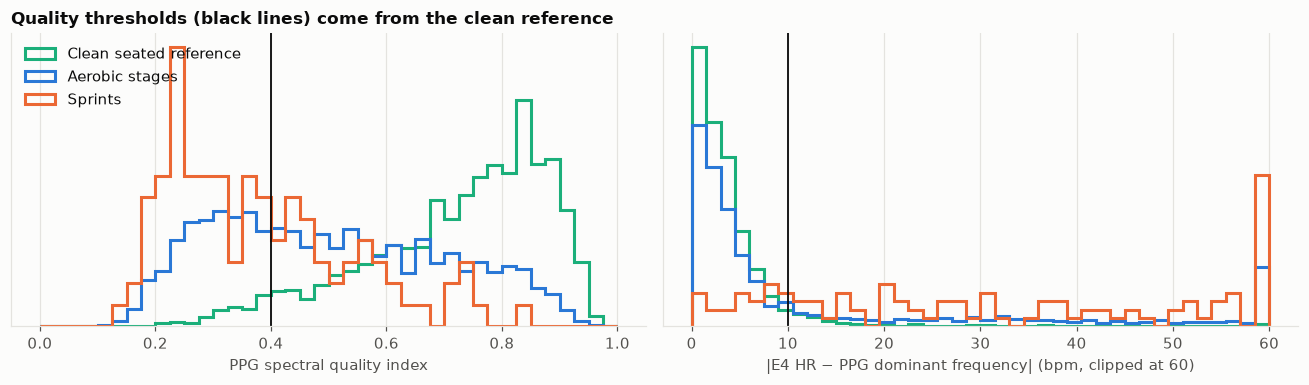

In [3]:
ref = w[w.state.isin(["SEATED_BASELINE", "SEATED_REST"]) & (w.ibi_coverage >= 0.7)]
print(f"Reference windows: {len(ref):,} from {ref.subject_id.nunique()} participants")
print("SQI 5th percentile:", round(ref.bvp_sqi.quantile(0.05), 3),
      "| agreement 95th percentile (bpm):", round(ref.hr_agreement_bpm.quantile(0.95), 1))

groups = [("Clean seated reference", ref, C["STRESS"]),
          ("Aerobic stages", w[w.state == "AEROBIC_STAGE"], C["AEROBIC"]),
          ("Sprints", w[w.state == "SPRINT"], C["ANAEROBIC"])]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for name, d, col in groups:
    axes[0].hist(d.bvp_sqi.dropna(), bins=np.linspace(0, 1, 41), density=True, histtype="step", lw=2, color=col, label=name)
    axes[1].hist(d.hr_agreement_bpm.dropna().clip(upper=60), bins=np.linspace(0, 60, 41), density=True, histtype="step", lw=2, color=col, label=name)
axes[0].axvline(Q.BVP_SQI_MIN, color=P.TEXT, lw=1.2); axes[0].set_xlabel("PPG spectral quality index")
axes[1].axvline(Q.HR_AGREEMENT_BPM, color=P.TEXT, lw=1.2); axes[1].set_xlabel("|E4 HR − PPG dominant frequency| (bpm, clipped at 60)")
for ax in axes: ax.set_yticks([]); ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left"); axes[0].set_title("Quality thresholds (black lines) come from the clean reference", loc="left")
fig.tight_layout(); P.save(fig, "02_quality_calibration"); plt.show()

## 3 · Cadence lock-in

The wrist moves once per foot-down, so the accelerometer's dominant frequency is the step rate (≈ 2 × rpm). If the
HR estimate sits on the cadence or the step rate while rhythmic movement is present, the optical sensor is most likely
tracking the pedals, not the heart. Those windows are rejected. Orange points away from the two lines were flagged
because the raw PPG's dominant frequency, rather than Empatica's HR, sat on the movement rhythm.

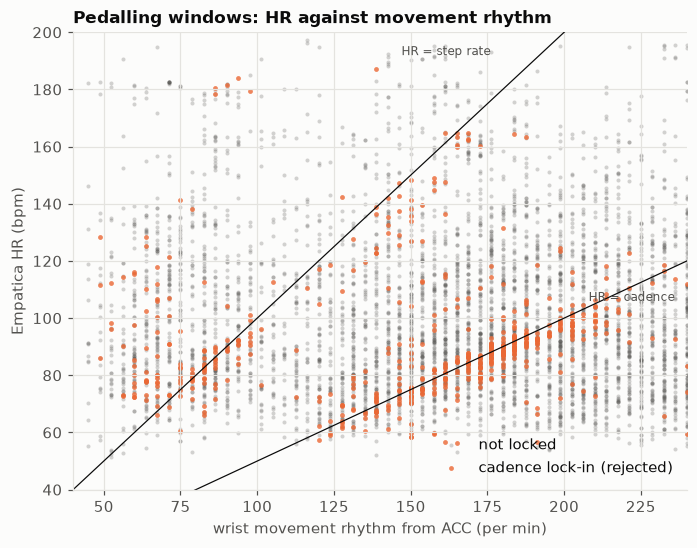

Lock-in share among pedalling windows with HR: 10.9%


In [4]:
ped = w[w.state.isin(["AEROBIC_STAGE", "UNLOADED_PEDALLING", "SPRINT"]) & w.hr_mean.notna()]
fig, ax = plt.subplots(figsize=(7.2, 5.4))
ok = ped[~ped.cadence_lock]; lk = ped[ped.cadence_lock]
ax.scatter(ok.acc_dom_freq_per_min, ok.hr_mean, s=7, color=P.TEXT_2, alpha=0.25, lw=0, label="not locked")
ax.scatter(lk.acc_dom_freq_per_min, lk.hr_mean, s=10, color=C["ANAEROBIC"], alpha=0.8, lw=0, label="cadence lock-in (rejected)")
xs = np.linspace(40, 240, 10)
ax.plot(xs, xs, color=P.TEXT, lw=0.8); ax.plot(xs, xs / 2, color=P.TEXT, lw=0.8)
ax.text(176, 192, "HR = step rate", fontsize=8, color=P.TEXT_2, ha="right"); ax.text(236, 106, "HR = cadence", fontsize=8, color=P.TEXT_2, ha="right")
ax.set_xlim(40, 240); ax.set_ylim(40, 200)
ax.set_xlabel("wrist movement rhythm from ACC (per min)"); ax.set_ylabel("Empatica HR (bpm)")
ax.set_title("Pedalling windows: HR against movement rhythm", loc="left"); ax.legend(loc="lower right")
P.save(fig, "02_cadence_lockin"); plt.show()
print(f"Lock-in share among pedalling windows with HR: {ped.cadence_lock.mean():.1%}")

## 4 · How much HR survives, by physiological state

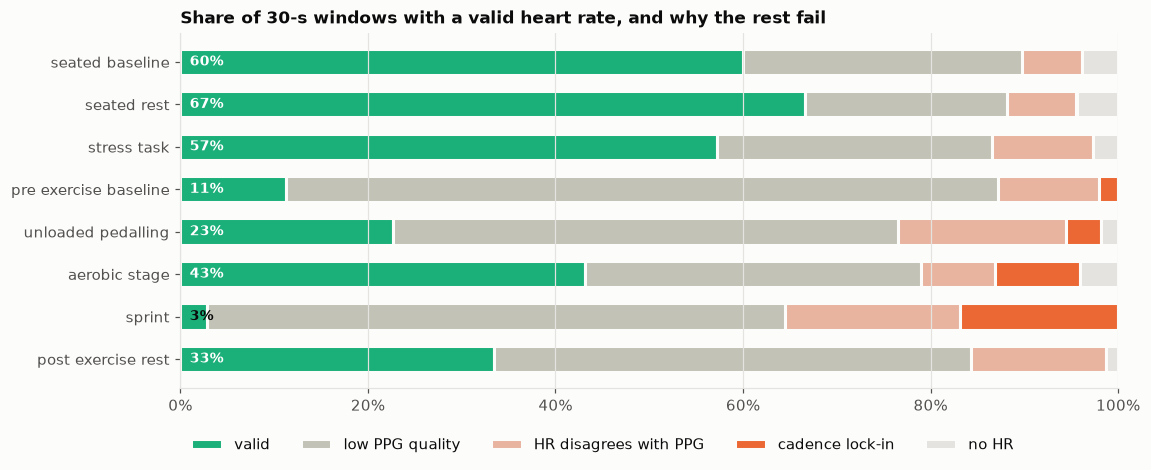

hr_fail_reason,valid,low PPG quality,HR disagrees with PPG,cadence lock-in,no HR
state,,,,,
SEATED_BASELINE,0.600,0.298,0.063,0.001,0.038
SEATED_REST,0.666,0.215,0.074,0.001,0.043
STRESS_TASK,0.572,0.293,0.108,0.000,0.027
PRE_EXERCISE_BASELINE,0.113,0.759,0.107,0.021,0.000
UNLOADED_PEDALLING,0.226,0.539,0.179,0.037,0.018
AEROBIC_STAGE,0.431,0.358,0.080,0.090,0.040
SPRINT,0.028,0.617,0.187,0.168,0.000
POST_EXERCISE_REST,0.335,0.509,0.144,0.000,0.013


In [5]:
order = ["SEATED_BASELINE", "SEATED_REST", "STRESS_TASK", "PRE_EXERCISE_BASELINE", "UNLOADED_PEDALLING",
         "AEROBIC_STAGE", "SPRINT", "POST_EXERCISE_REST"]
reasons = ["valid", "low PPG quality", "HR disagrees with PPG", "cadence lock-in", "no HR"]
ct = pd.crosstab(w.state, w.hr_fail_reason, normalize="index").reindex(order)[reasons]
colors = {"valid": C["STRESS"], "low PPG quality": "#c3c2b7", "HR disagrees with PPG": "#e8b4a0",
          "cadence lock-in": C["ANAEROBIC"], "no HR": "#e4e3df"}
fig, ax = plt.subplots(figsize=(11, 4.2))
left = np.zeros(len(ct))
for r in reasons:
    ax.barh(range(len(ct)), ct[r], left=left, color=colors[r], height=0.62, label=r, edgecolor=P.SURFACE, lw=2)
    left += ct[r].to_numpy()
for i, v in enumerate(ct["valid"]):
    ax.text(0.01, i, f"{v:.0%}", va="center", fontsize=9, color="white" if v > 0.08 else P.TEXT, fontweight="bold")
ax.set_yticks(range(len(ct)), [s.replace("_", " ").lower() for s in ct.index]); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.1)); ax.grid(axis="y", visible=False)
ax.set_title("Share of 30-s windows with a valid heart rate, and why the rest fail", loc="left")
P.save(fig, "02_hr_validity_by_state"); plt.show()
ct.round(3)

- Seated, about **60–67% of windows** have a trustworthy HR (Empatica drops beats even at rest; IBI coverage at rest
  is only ~58%).
- During **aerobic stages, 43%** survive. Low PPG quality is the main reason for rejection, followed by cadence lock-in.
- During **sprints, only ~3%**. Wrist PPG cannot measure heart rate during all-out cycling. The anaerobic HR response
  can only be studied *after* the sprint, during the cooldown.

## 5 · Per-participant HR availability in the active part of each protocol

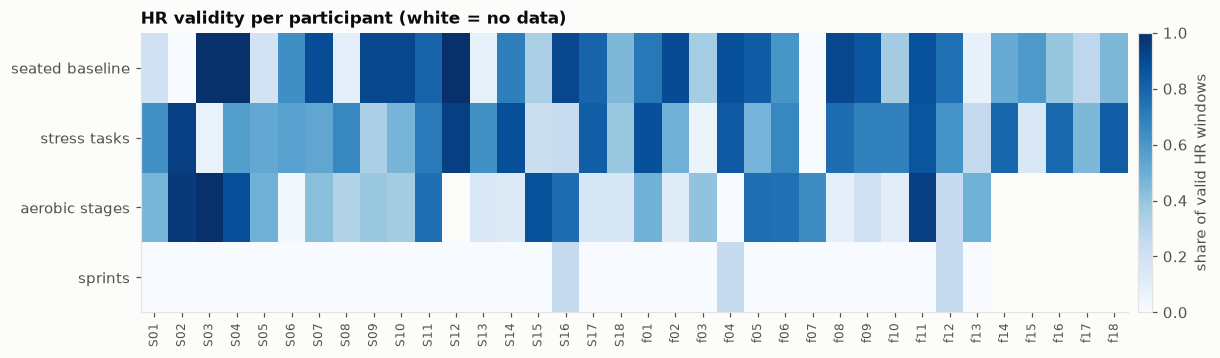

In [6]:
active = w[w.state.isin(["STRESS_TASK", "AEROBIC_STAGE", "SPRINT", "SEATED_BASELINE"])]
mat = active.pivot_table(index="subject_id", columns="state", values="hr_valid", aggfunc="mean")
mat = mat[["SEATED_BASELINE", "STRESS_TASK", "AEROBIC_STAGE", "SPRINT"]]
fig, ax = plt.subplots(figsize=(12, 3.3))
im = ax.imshow(mat.T.to_numpy(dtype=float), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(4), ["seated baseline", "stress tasks", "aerobic stages", "sprints"])
ax.set_xticks(range(len(mat)), mat.index, rotation=90, fontsize=8); ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("share of valid HR windows")
ax.set_title("HR validity per participant (white = no data)", loc="left")
P.save(fig, "02_hr_validity_matrix"); plt.show()

## 6 · Other signals

In [7]:
other = w.groupby("state")[["eda_valid", "temp_valid", "acc_valid"]].mean().reindex(order)
print("Share of valid windows per signal and state")
other.round(2)

Share of valid windows per signal and state


,eda_valid,temp_valid,acc_valid
state,,,
SEATED_BASELINE,0.940,0.610,1.000
SEATED_REST,0.990,0.960,1.000
STRESS_TASK,0.990,0.960,1.000
PRE_EXERCISE_BASELINE,0.970,0.600,0.970
UNLOADED_PEDALLING,0.960,0.710,0.980
AEROBIC_STAGE,0.980,0.910,1.000
SPRINT,0.940,0.780,0.960
POST_EXERCISE_REST,1.000,0.940,0.980


EDA and ACC are valid in ≥ 94% of windows in every state. Skin temperature loses windows mainly to the 5-min
equilibration rule, which hits the seated baseline and pre-exercise periods because they sit at the start of each
recording, plus the sessions with fault codes.

## 7 · Is HRV feasible?

HRV needs long, uninterrupted beat series. Rule (segment level, `src/signals/processing.hrv_time_domain`): at least
60 clean beats, coverage ≥ 50%, only consecutive beats differenced, ectopic-like jumps (> 20%) removed.

In [8]:
sf = pd.read_csv(PROCESSED / "segments_features.csv")
sf["hrv_ok"] = sf.rmssd_ms.notna()
hrv = sf.groupby("state").agg(segments=("hrv_ok", "size"), hrv_feasible=("hrv_ok", "mean"),
                              median_rmssd_ms=("rmssd_ms", "median")).reindex(order)
hrv.round(2)

,segments,hrv_feasible,median_rmssd_ms
state,,,
SEATED_BASELINE,37,0.590,44.310
SEATED_REST,72,0.690,45.740
STRESS_TASK,162,0.230,38.850
PRE_EXERCISE_BASELINE,12,0.000,NaN
UNLOADED_PEDALLING,196,0.100,31.160
AEROBIC_STAGE,224,0.170,29.010
SPRINT,106,0.000,NaN
POST_EXERCISE_REST,61,0.160,23.410


HRV is computable in a reasonable share of seated stress-protocol segments only. Where Empatica's beats do pass the
rule during exercise, the RMSSD values are physiologically implausible: ~25–35 ms at HR ~130 bpm, where values
< 10 ms would be expected. PPG beat-timing jitter and the 15.6-ms quantisation dominate the variability there.
**Decision: HRV is analysed only within the seated stress protocol** (baseline, rests and the TMCT, which is long enough).

## 8 · Sensitivity check: does the quality rule recover the expected exercise physiology?

This is not used to select data. In the aerobic V1 incremental test, HR should rise with workload. Compare all
windows (Phase 1 view) with valid windows only:

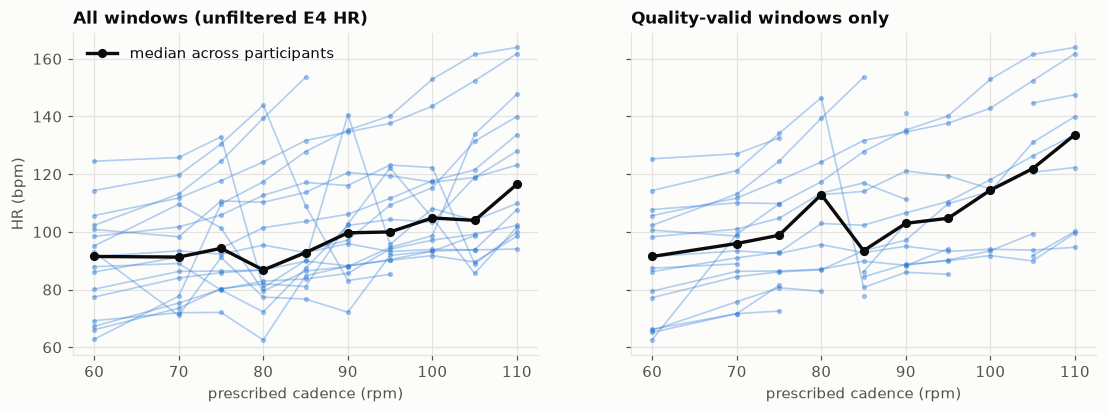

median per-participant Spearman rho (rpm vs HR): all = 0.87 | valid only = 0.95


In [9]:
a = w[(w.condition == "AEROBIC") & (w.cohort == "V1") & w.segment.str.match(r"rpm_\d+$")].copy()
a["rpm"] = a.segment.str[4:].astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (title, d) in zip(axes, [("All windows (unfiltered E4 HR)", a), ("Quality-valid windows only", a[a.hr_valid])]):
    per = d.groupby(["subject_id", "rpm"]).hr_mean.mean().unstack()
    for _, row in per.iterrows():
        ax.plot(row.index, row.values, color=C["AEROBIC"], alpha=0.35, lw=1.1, marker="o", ms=2.5)
    ax.plot(per.columns, per.median(), color=P.TEXT, lw=2.2, marker="o", ms=5, label="median across participants")
    ax.set_title(title, loc="left"); ax.set_xlabel("prescribed cadence (rpm)")
axes[0].set_ylabel("HR (bpm)"); axes[0].legend(loc="upper left")
P.save(fig, "02_hr_staircase_filtered"); plt.show()

from scipy.stats import spearmanr
def rho(d):
    per = d.groupby(["subject_id", "rpm"]).hr_mean.mean().reset_index()
    return per.groupby("subject_id").apply(lambda g: spearmanr(g.rpm, g.hr_mean).statistic if len(g) >= 4 else np.nan, include_groups=False)
print("median per-participant Spearman rho (rpm vs HR): all =", round(rho(a).median(), 2),
      "| valid only =", round(rho(a[a.hr_valid]).median(), 2))

Filtering on signal quality alone, without using the expected result, makes the incremental staircase clearer
(median per-participant rank correlation between cadence and HR: 0.87 unfiltered → 0.95 valid-only). The dip at
85 rpm in the right panel is a composition effect: fewer participants have valid windows at that stage, so the
median is taken over a different subset.
That is independent evidence that the rule removes artefact rather than physiology. Some participants still show
flat, low curves with good signal quality (e.g. S15). Those are kept: the data cannot prove them wrong, and
removing them would bias results toward the textbook answer.

In [10]:
# Inclusion matrix: participant x condition x signal -> share of valid windows in the active state
act = w[w.state.isin(["STRESS_TASK", "AEROBIC_STAGE", "SPRINT", "SEATED_BASELINE", "SEATED_REST"])]
inc = act.groupby(["subject_id", "condition", "state"])[["hr_valid", "eda_valid", "temp_valid", "acc_valid"]].mean().round(3)
inc.to_csv(PROCESSED / "inclusion_matrix.csv")
print("Saved inclusion_matrix.csv:", inc.shape)

Saved inclusion_matrix.csv: (169, 4)


## Summary

| Signal | Rule | Valid in active states |
|---|---|---|
| HR (Empatica) | PPG SQI ≥ 0.40, agreement ≤ 10 bpm, no cadence lock-in | seated ~60–67% · stress tasks ~57% · aerobic ~43% · sprints ~3% |
| HRV (Empatica IBI) | ≥ 60 beats, ≥ 50% coverage, consecutive beats | seated stress protocol only |
| EDA | < 10% of samples below 0.05 µS | ≥ 94% |
| Skin temperature | no fault codes, not in the first 5 min | 60–96% |
| ACC | < 5% saturated samples | ≥ 96% |

Outputs: `data/processed/windows.csv` (all windows with flags) and `inclusion_matrix.csv`.